# 04 · Explanation Stability Under Input Perturbations

**Objective.** Apply identical, semantically mild perturbations to each explanation method and export per-sample similarity metrics. This notebook produces the raw table used by the proposed TCERS score.

## Perturbation families

| Family | Values | Implementation | Rationale |
|---|---|---|---|
| Rotation | −15°, −10°, −5°, 5°, 10°, 15° | `TF.rotate` | Camera roll and framing jitter |
| Brightness | 0.8×, 1.2× | `TF.adjust_brightness` | Exposure change |
| Gaussian noise | σ = 0.01, 0.03, 0.05 | Additive Gaussian in normalized space | Sensor noise |
| Resize | 128, 180, 256 px | Resize then restore to 224 px | Resolution and compression loss |

All perturbations are applied to the **normalized** batch. Noise is paired across methods by re-seeding the generator for each method, so every method sees the same noise realization for a given sample.

## Stability metrics

| Metric | Range | Interpretation |
|---|---|---|
| SSIM | [0, 1] | Structural agreement of normalized maps |
| Spearman ρ | [−1, 1] | Rank-order agreement of pixel importance |
| Cosine similarity | [−1, 1] | Global orientation agreement |
| IoU at τ = 0.5 | [0, 1] | Overlap of high-importance regions |
| Prediction consistency | [0, 1] | Fraction of transformations that preserve the predicted class |

**Exclusion rule.** Similarity metrics are computed only when the perturbed prediction equals the original prediction. Prediction consistency is reported separately, so a method cannot gain stability credit by changing the classifier's decision.

## Artifacts

- `experiments/results/stability_<method>.csv` (one file per method)
- `experiments/results/stability_raw.csv` (combined)
- `experiments/results/stability_summary.csv`
- `experiments/results/stability_by_parameter.csv`
- `experiments/results/stability_overall.csv`
- `figures/stability_ssim.png`
- `figures/stability_ssim_heatmap.png`
- `figures/stability_prediction_consistency.png`

## Environment and checkpoint

The checkpoint is loaded once and fixed in evaluation mode. The number of samples is deliberately kept small by default because Occlusion Sensitivity performs many forward passes per perturbation. Increase `NUM_SAMPLES` for a final run and record the change.

In [1]:
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image as DisplayImage, display

from src.config import ExperimentConfig
from src.data.oxford_pets import load_oxford_pets
from src.evaluation.runner import evaluate_transformations
from src.explainers.methods import GradCAM, integrated_gradients, occlusion_sensitivity
from src.models.resnet import build_resnet18
from src.perturbations.transforms import make_perturbations
from src.utils import device, seed_everything

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300})

config = ExperimentConfig()
config.create_directories()
seed_everything(config.seed)

checkpoint_path = config.checkpoint_root / "resnet18_best.pth"
if not checkpoint_path.exists():
    raise FileNotFoundError("Checkpoint missing. Run notebook 02 or `python -m src.train` first.")

model = build_resnet18(config.num_classes)
state = torch.load(checkpoint_path, map_location=device())
model.load_state_dict(state["model_state_dict"])
model.to(device()).eval()
print(f"Loaded checkpoint: {checkpoint_path}")
print(f"Device: {device()}")

Loaded checkpoint: checkpoints\resnet18_best.pth
Device: cpu


## Sample selection

The first `NUM_SAMPLES` test images are used for a paired design: every method is evaluated on exactly the same images and perturbations. The sample indices are saved with the results so the analysis can be reproduced.

In [2]:
NUM_SAMPLES = 8
METHOD_NAMES = ["Grad-CAM", "Integrated Gradients", "Occlusion"]

_, _, test_loader = load_oxford_pets(
    config.data_root, config.image_size, config.batch_size, config.num_workers, seed=config.seed
)

subset = torch.utils.data.Subset(test_loader.dataset, list(range(NUM_SAMPLES)))
batch_loader = torch.utils.data.DataLoader(subset, batch_size=NUM_SAMPLES, shuffle=False)
images, labels = next(iter(batch_loader))
print(f"Samples: {NUM_SAMPLES} | label counts: {np.bincount(labels.numpy(), minlength=2).tolist()}")

Samples: 8 | label counts: [8, 0]


## Build explainers

The explainer configuration matches Notebook 03. Occlusion uses a $32\times32$ patch with stride 16; this is a methodological choice that should be reported with the results.

In [3]:
grad_cam = GradCAM(model, model.layer4[-1])

explainers = {
    "Grad-CAM": lambda batch: grad_cam(batch),
    "Integrated Gradients": lambda batch: integrated_gradients(model, batch, steps=16),
    "Occlusion": lambda batch: occlusion_sensitivity(model, batch, patch_size=32, stride=16),
}
list(explainers)

['Grad-CAM', 'Integrated Gradients', 'Occlusion']

## Run the stability evaluation

For each method, the perturbation list is recreated with a freshly seeded noise generator. This makes the random noise component paired across methods instead of advancing a shared generator.

In [4]:
results_by_method = {}
for method_name in METHOD_NAMES:
    perturbations = make_perturbations(
        noise_generator=torch.Generator(device=device()).manual_seed(config.seed)
    )
    file_stem = method_name.replace(" ", "_").replace("-", "_").lower()
    output_csv = config.output_root / f"stability_{file_stem}.csv"
    frame = evaluate_transformations(
        model,
        images,
        explainers[method_name],
        perturbations,
        device(),
        method=method_name,
        output_csv=output_csv,
    )
    results_by_method[method_name] = frame
    print(f"{method_name:>22}: {len(frame):>4} rows -> {output_csv.name}")

              Grad-CAM:  112 rows -> stability_grad_cam.csv


  Integrated Gradients:  112 rows -> stability_integrated_gradients.csv


             Occlusion:  112 rows -> stability_occlusion.csv


In [5]:
raw_results = pd.concat(results_by_method.values(), ignore_index=True)
raw_path = config.output_root / "stability_raw.csv"
raw_results.to_csv(raw_path, index=False)
print(f"Combined rows: {len(raw_results)} -> {raw_path}")
raw_results.head(10)

Combined rows: 336 -> experiments\results\stability_raw.csv


,sample,transformation,parameter,method,prediction_unchanged,original_confidence,transformed_confidence,ssim,iou,spearman,cosine
0,0,rotation,-15.0,Grad-CAM,True,0.992697,0.982663,0.806451,0.898666,0.926341,0.995248
1,1,rotation,-15.0,Grad-CAM,True,0.999851,0.997552,0.788084,0.641369,0.917006,0.955873
2,2,rotation,-15.0,Grad-CAM,True,0.999972,0.999424,0.868198,0.627621,0.952354,0.966144
3,3,rotation,-15.0,Grad-CAM,True,0.981512,0.603166,0.270185,0.046760,0.058271,0.388926
4,4,rotation,-15.0,Grad-CAM,True,0.999983,0.995818,0.855375,0.687505,0.927149,0.974418
5,5,rotation,-15.0,Grad-CAM,True,0.517561,0.803079,0.520900,0.624015,0.618737,0.922005
6,6,rotation,-15.0,Grad-CAM,False,0.600604,0.859821,NaN,NaN,NaN,NaN
7,7,rotation,-15.0,Grad-CAM,True,0.999913,0.998468,0.955590,0.818140,0.980559,0.991804
8,0,rotation,-10.0,Grad-CAM,True,0.992697,0.971972,0.853182,0.898688,0.934405,0.995971
9,1,rotation,-10.0,Grad-CAM,True,0.999851,0.999054,0.883070,0.753495,0.955402,0.982994


## Summary by method and transformation family

`valid_pairs` counts the prediction-preserving pairs that actually contribute to the similarity means. `prediction_consistency` uses all observations, including excluded ones, and is therefore the correct companion metric to the conditional similarity scores.

In [6]:
valid_results = raw_results[raw_results["prediction_unchanged"]].copy()

summary = (
    raw_results.groupby(["method", "transformation"])
    .agg(
        n=("sample", "size"),
        prediction_consistency=("prediction_unchanged", "mean"),
        valid_pairs=("ssim", "count"),
        ssim_mean=("ssim", "mean"),
        ssim_std=("ssim", "std"),
        spearman_mean=("spearman", "mean"),
        cosine_mean=("cosine", "mean"),
        iou_mean=("iou", "mean"),
    )
    .reset_index()
)
summary.to_csv(config.output_root / "stability_summary.csv", index=False)
summary

,method,transformation,n,prediction_consistency,valid_pairs,ssim_mean,ssim_std,spearman_mean,cosine_mean,iou_mean
0,Grad-CAM,brightness,16,0.687500,11,0.691917,0.133690,0.819105,0.919692,0.583426
1,Grad-CAM,noise,24,0.958333,23,0.986065,0.034048,0.992983,0.998864,0.972499
2,Grad-CAM,resize,24,1.000000,24,0.827467,0.196144,0.847680,0.925070,0.735494
3,Grad-CAM,rotation,48,0.937500,45,0.804636,0.172326,0.861786,0.921631,0.690432
4,Integrated Gradients,brightness,16,0.687500,11,0.467071,0.196985,-0.007981,0.330218,0.006203
5,Integrated Gradients,noise,24,0.958333,23,0.898027,0.059321,0.844752,0.903651,0.405666
6,Integrated Gradients,resize,24,1.000000,24,0.791372,0.126145,0.785447,0.805991,0.190346
7,Integrated Gradients,rotation,48,0.937500,45,0.655882,0.067978,0.542234,0.582498,0.020378
8,Occlusion,brightness,16,0.687500,11,0.620419,0.287955,0.379585,0.617556,0.287374
9,Occlusion,noise,24,0.958333,23,0.975050,0.049262,0.971852,0.997102,0.919215


In [7]:
overall = (
    raw_results.groupby("method")
    .agg(
        observations=("sample", "size"),
        prediction_consistency=("prediction_unchanged", "mean"),
        valid_pairs=("ssim", "count"),
        ssim_mean=("ssim", "mean"),
        ssim_std=("ssim", "std"),
        spearman_mean=("spearman", "mean"),
        cosine_mean=("cosine", "mean"),
        iou_mean=("iou", "mean"),
    )
    .reset_index()
)
overall.to_csv(config.output_root / "stability_overall.csv", index=False)
overall

,method,observations,prediction_consistency,valid_pairs,ssim_mean,ssim_std,spearman_mean,cosine_mean,iou_mean
0,Grad-CAM,112,0.919643,103,0.838431,0.176775,0.883237,0.939471,0.752490
1,Integrated Gradients,112,0.919643,103,0.721360,0.164927,0.607697,0.679345,0.144504
2,Occlusion,112,0.919643,103,0.735972,0.253191,0.727780,0.857383,0.608846


## Parameter-level summary

Aggregating by transformation family hides the dose–response relationship. The parameter-level table exposes how stability changes with rotation angle, brightness factor, noise level, and resize resolution.

In [8]:
parameter_summary = (
    raw_results.groupby(["method", "transformation", "parameter"])
    .agg(
        n=("sample", "size"),
        prediction_consistency=("prediction_unchanged", "mean"),
        valid_pairs=("ssim", "count"),
        ssim_mean=("ssim", "mean"),
        spearman_mean=("spearman", "mean"),
        cosine_mean=("cosine", "mean"),
    )
    .reset_index()
)
parameter_summary.to_csv(config.output_root / "stability_by_parameter.csv", index=False)
parameter_summary

,method,transformation,parameter,n,prediction_consistency,valid_pairs,ssim_mean,spearman_mean,cosine_mean
0,Grad-CAM,brightness,0.80,8,0.625,5,0.698680,0.826662,0.928753
1,Grad-CAM,brightness,1.20,8,0.750,6,0.686280,0.812807,0.912141
2,Grad-CAM,noise,0.01,8,1.000,8,0.996201,0.998660,0.999493
3,Grad-CAM,noise,0.03,8,0.875,7,0.993738,0.998822,0.999651
4,Grad-CAM,noise,0.05,8,1.000,8,0.969216,0.982195,0.997546
5,Grad-CAM,resize,128.00,8,1.000,8,0.695331,0.698440,0.844366
6,Grad-CAM,resize,180.00,8,1.000,8,0.853833,0.882717,0.944386
7,Grad-CAM,resize,256.00,8,1.000,8,0.933235,0.961881,0.986458
8,Grad-CAM,rotation,-15.00,8,0.875,7,0.723540,0.768631,0.884917
9,Grad-CAM,rotation,-10.00,8,0.875,7,0.854410,0.937295,0.981159


## Visual diagnostics

The box plot shows the distribution of prediction-preserving SSIM values. The heatmap summarizes mean SSIM by method and transformation family. The bar chart reports prediction consistency separately.

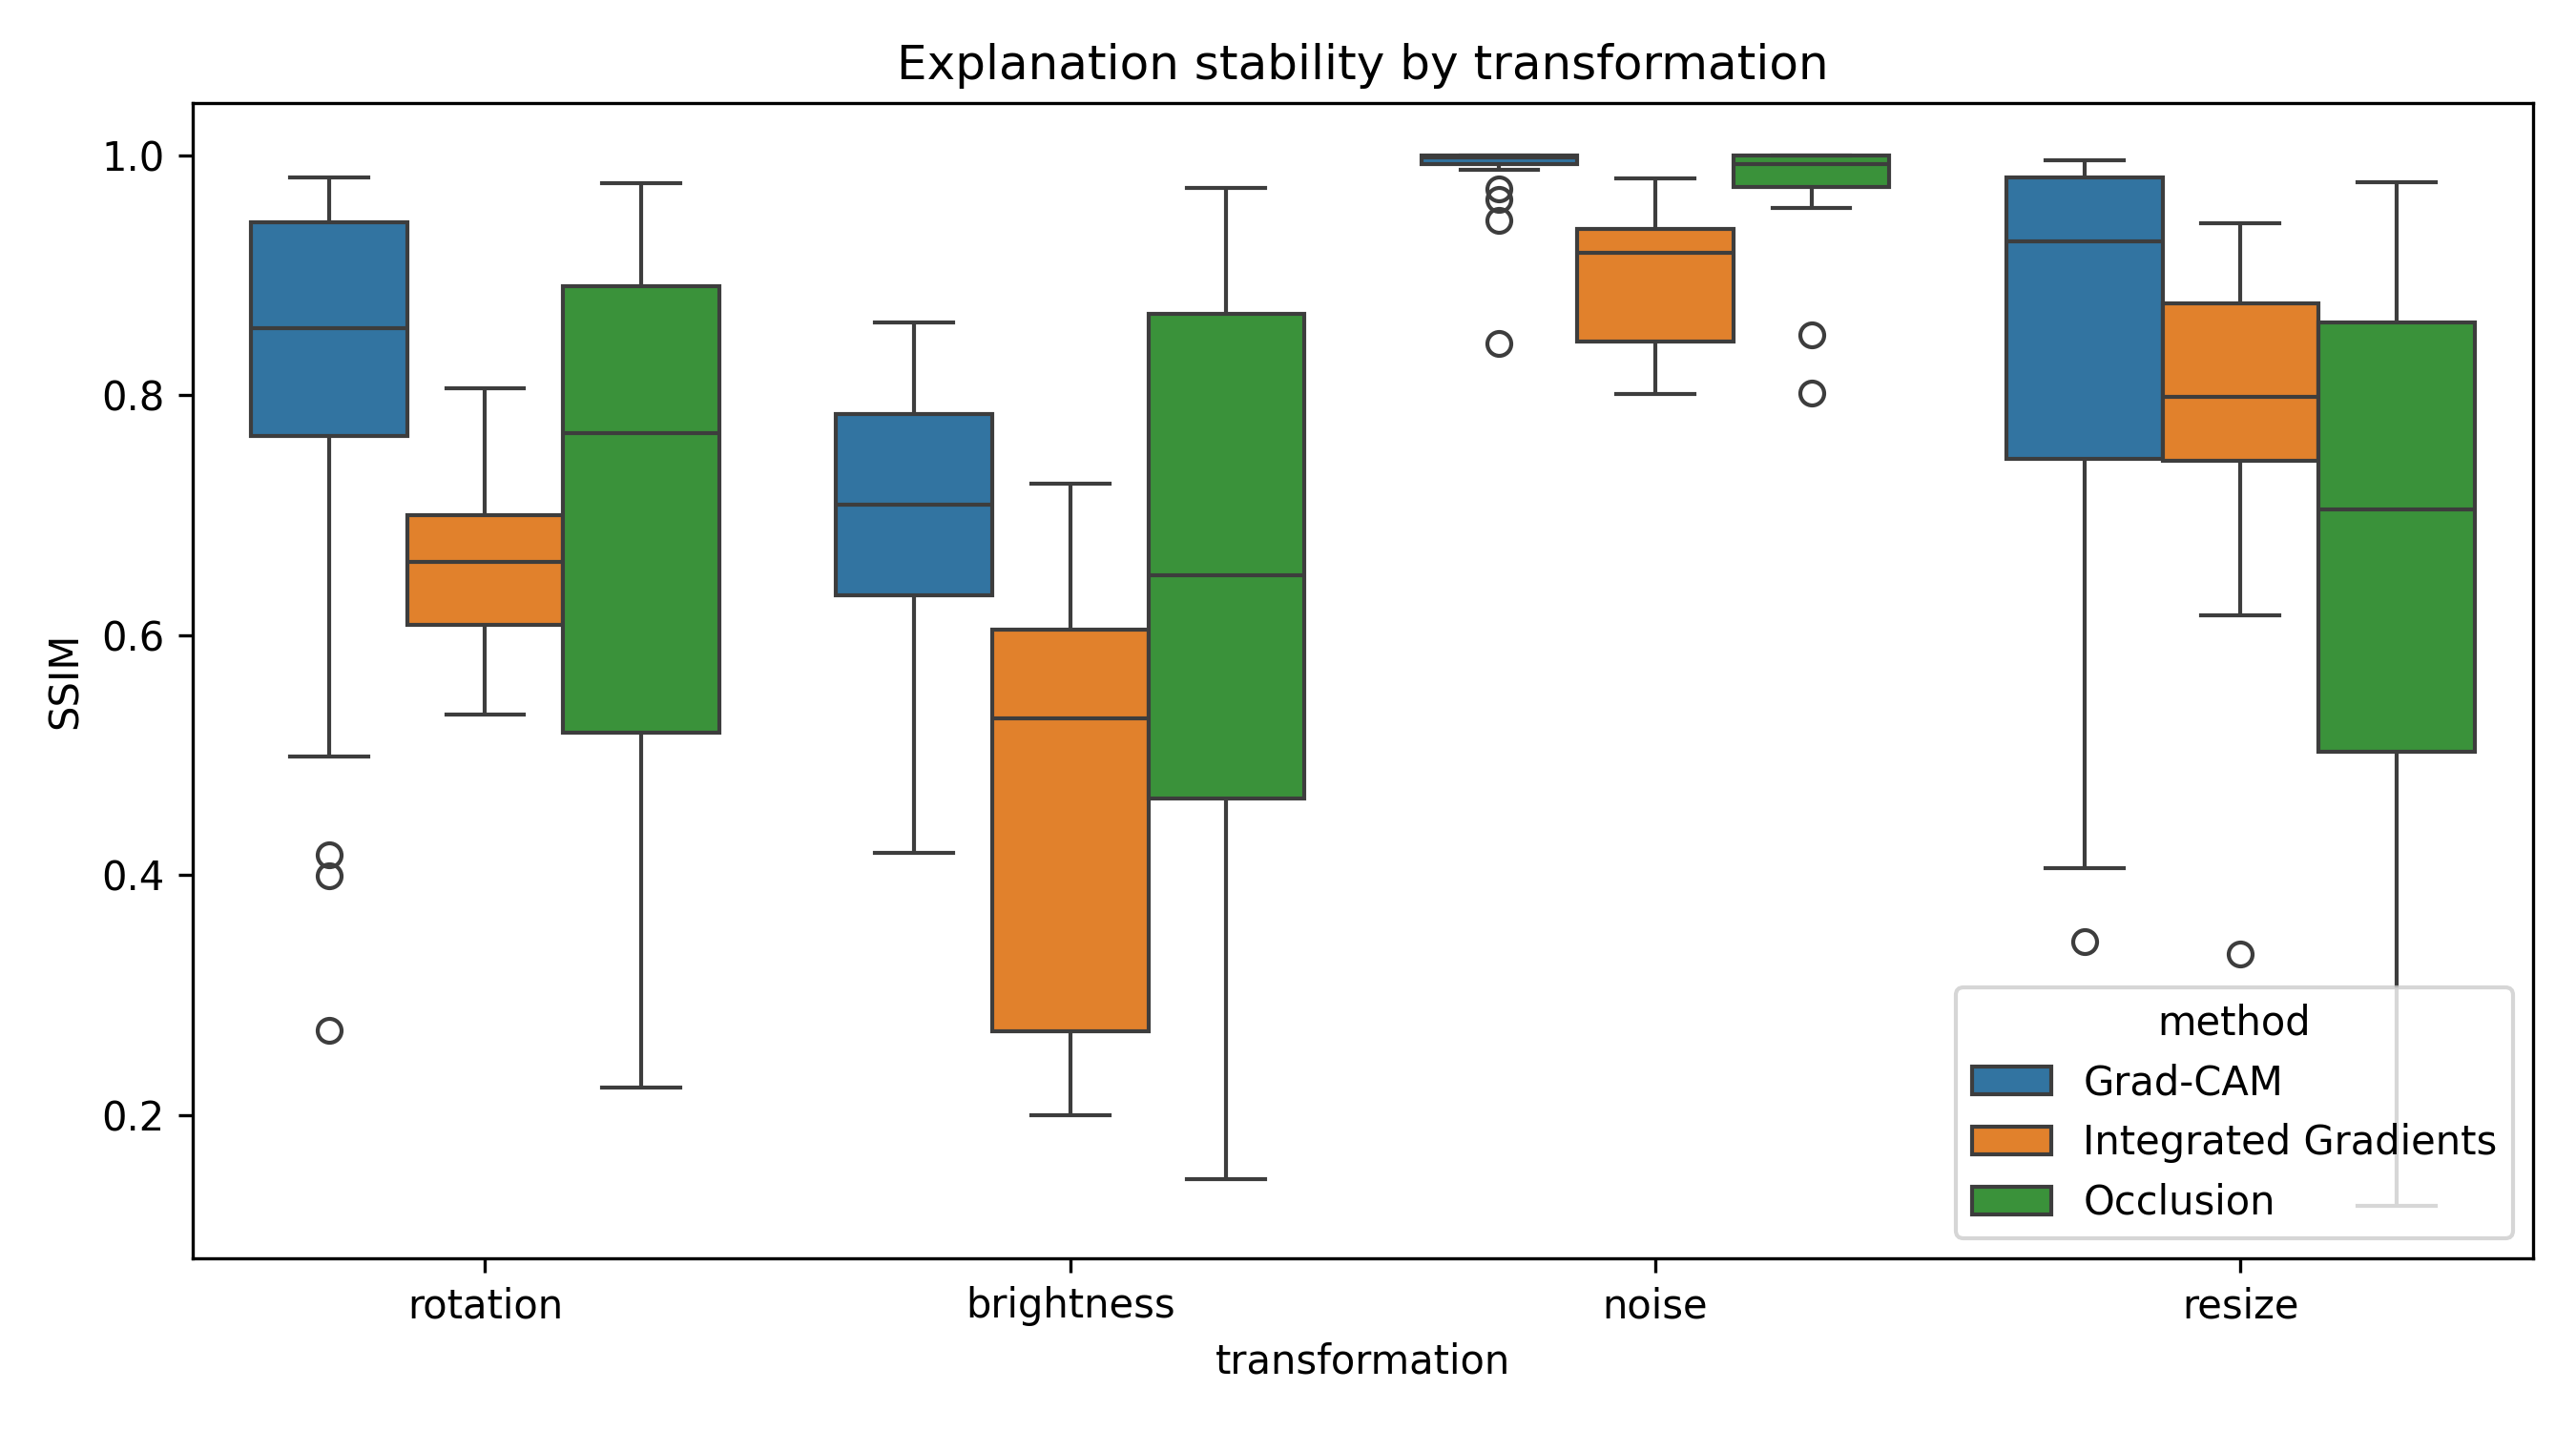

In [9]:
from src.visualization.plots import plot_stability

if valid_results.empty:
    raise RuntimeError("No prediction-preserving pairs were found; stability metrics cannot be plotted.")

plot_stability(valid_results, Path("figures") / "stability_ssim.png")
display(DisplayImage(filename=str(Path("figures") / "stability_ssim.png")))

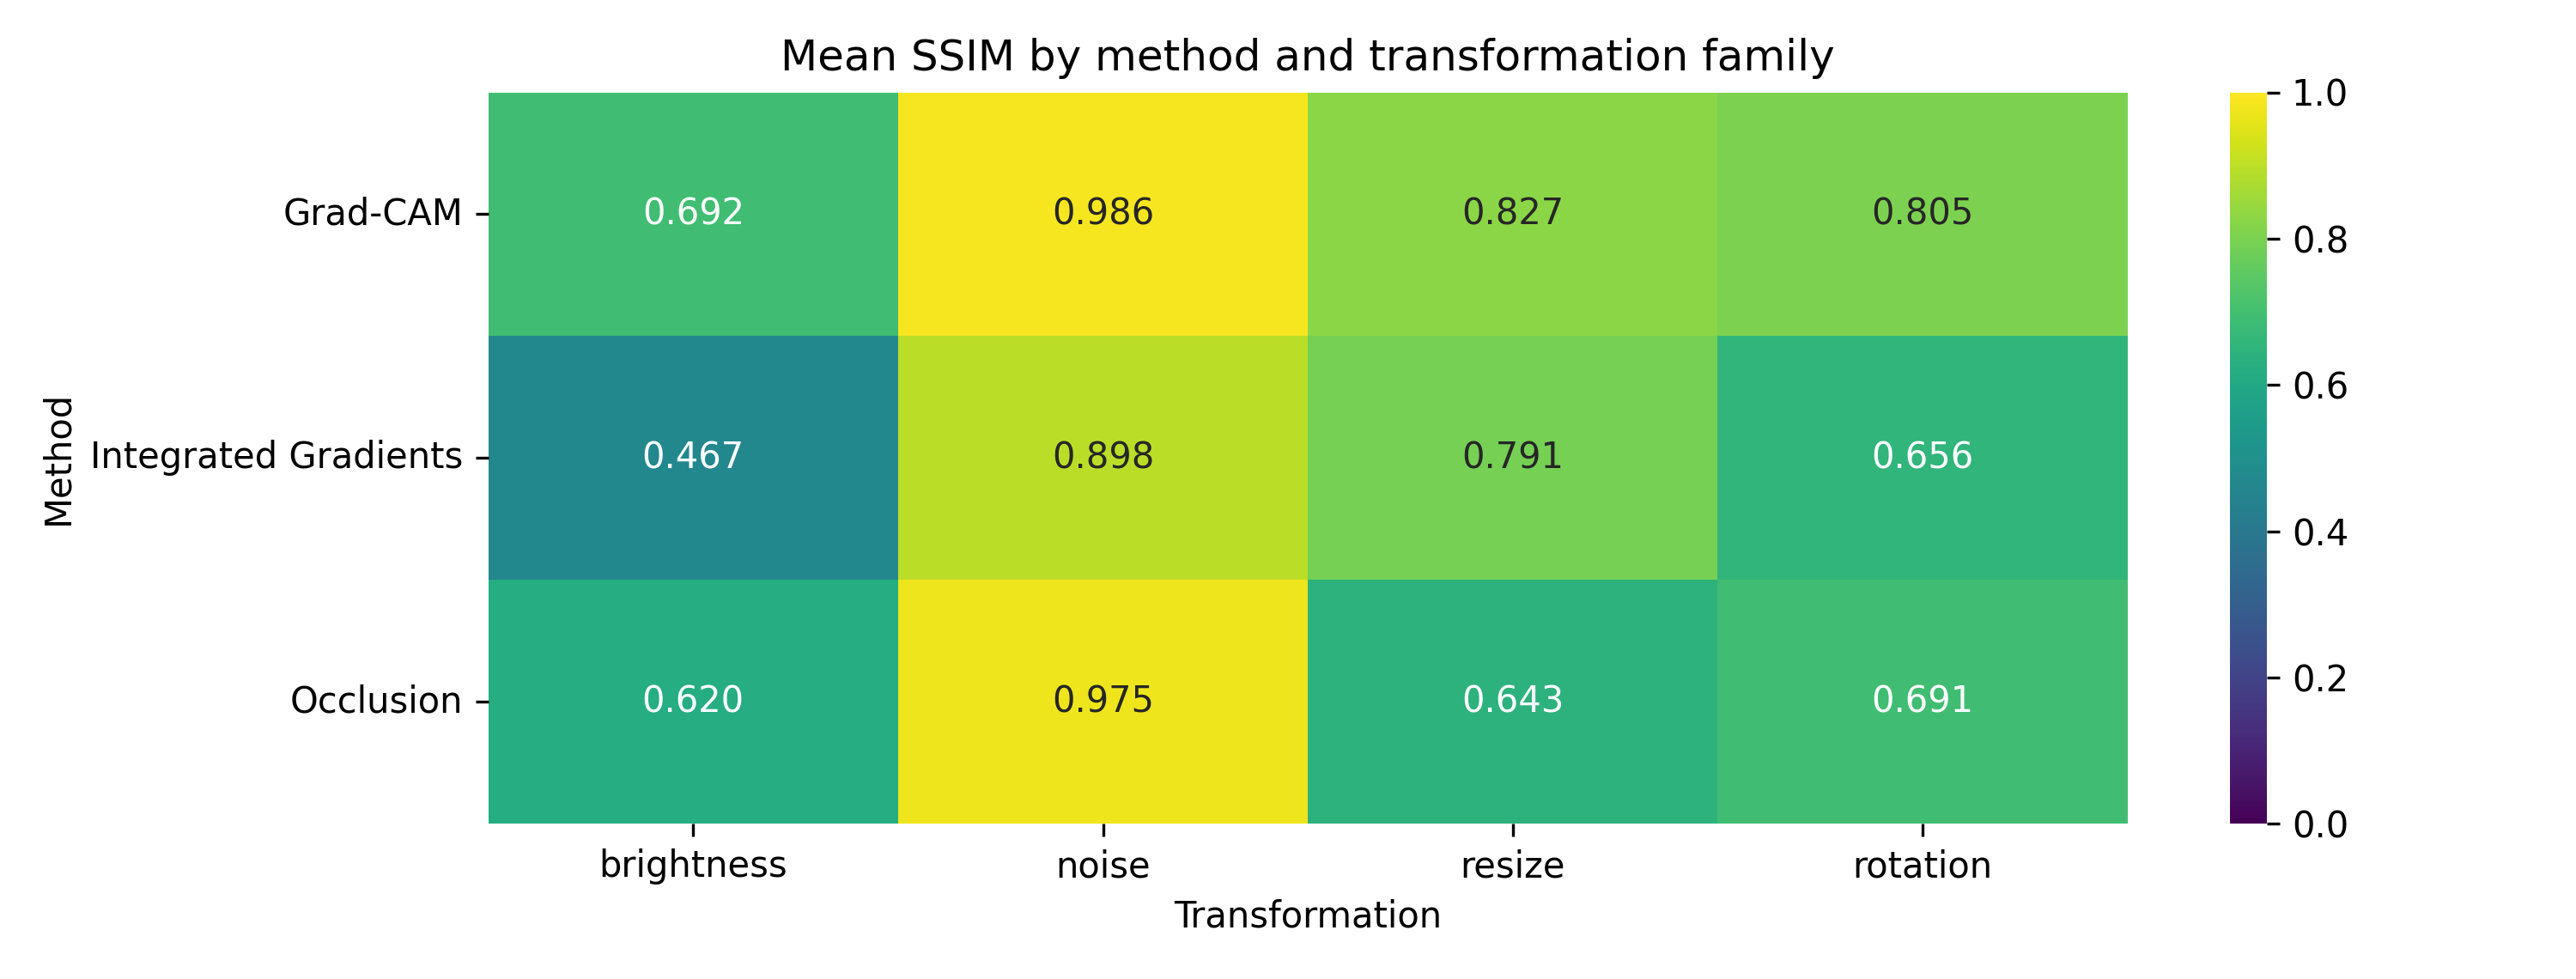

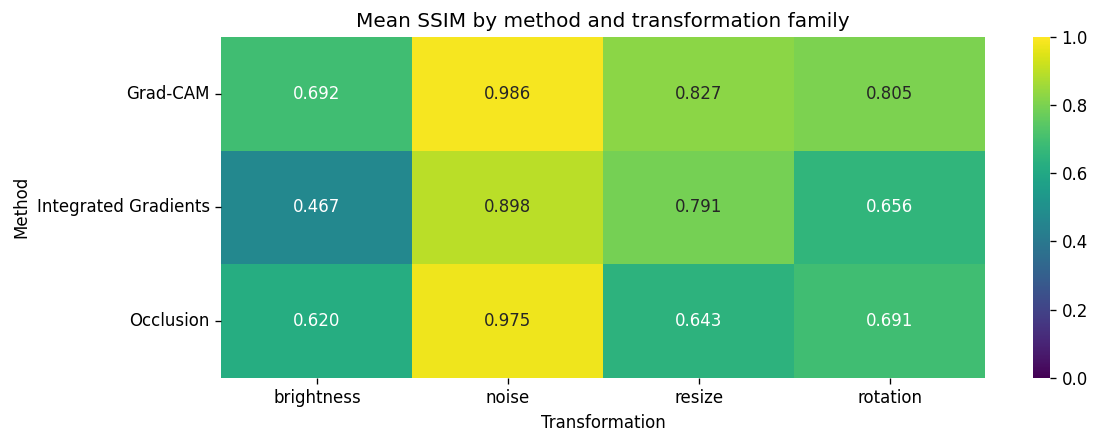

In [10]:
ssim_pivot = valid_results.pivot_table(
    index="method", columns="transformation", values="ssim", aggfunc="mean"
)
figure, axis = plt.subplots(figsize=(10, 3.8))
sns.heatmap(ssim_pivot, annot=True, fmt=".3f", cmap="viridis", vmin=0, vmax=1, ax=axis)
axis.set(title="Mean SSIM by method and transformation family", xlabel="Transformation", ylabel="Method")
figure.tight_layout()
figure.savefig(Path("figures") / "stability_ssim_heatmap.png", dpi=300)
display(DisplayImage(filename=str(Path("figures") / "stability_ssim_heatmap.png")))

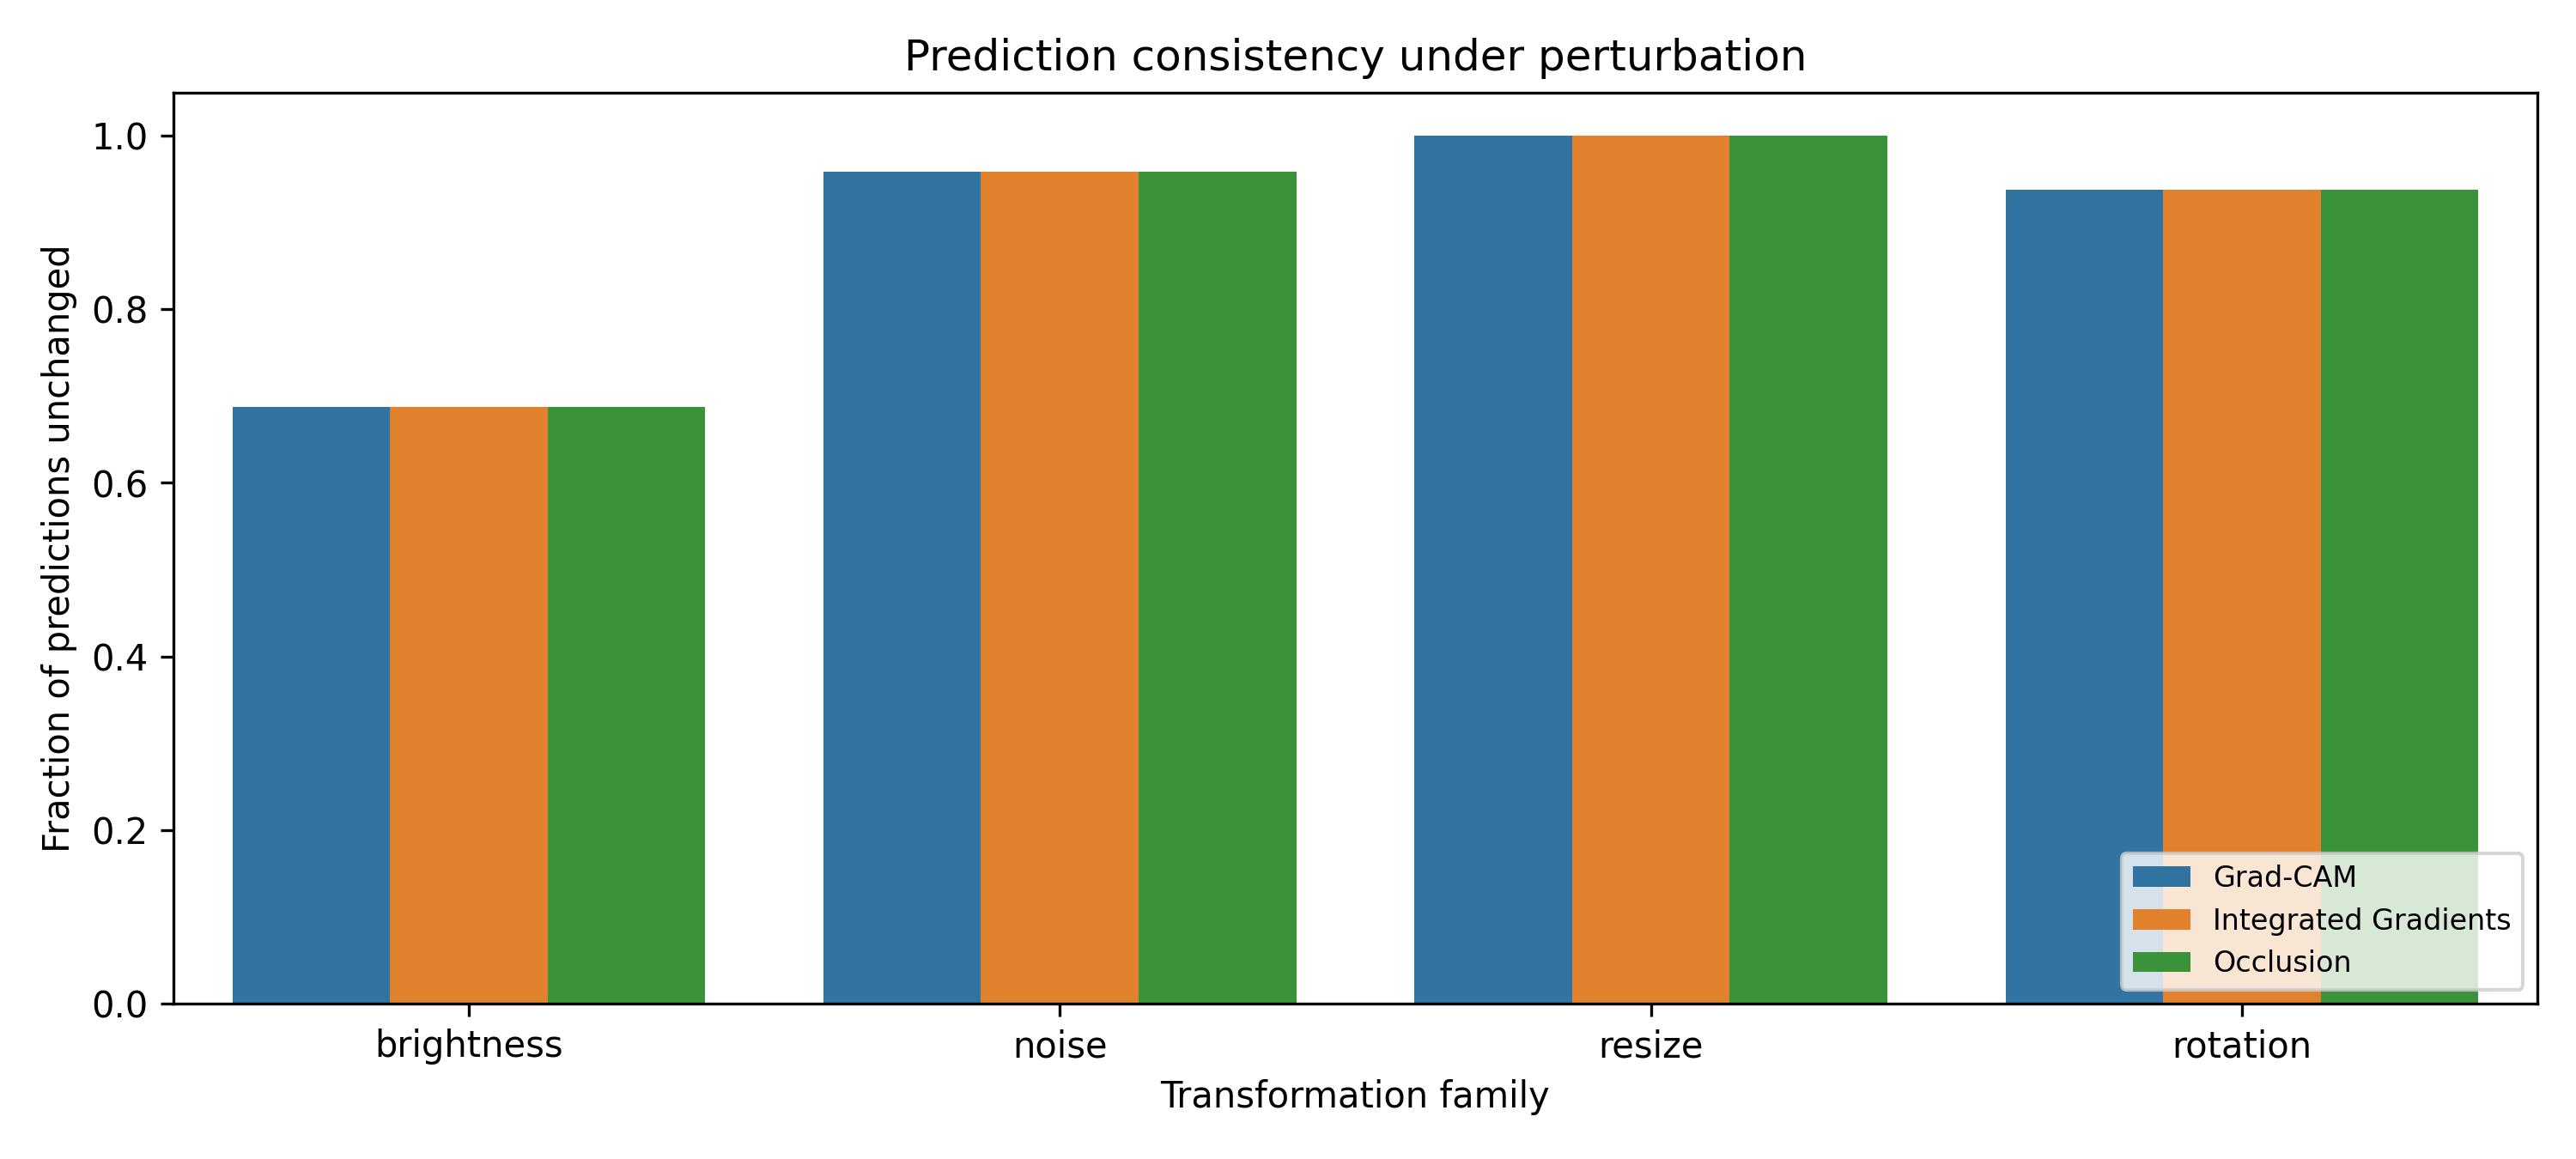

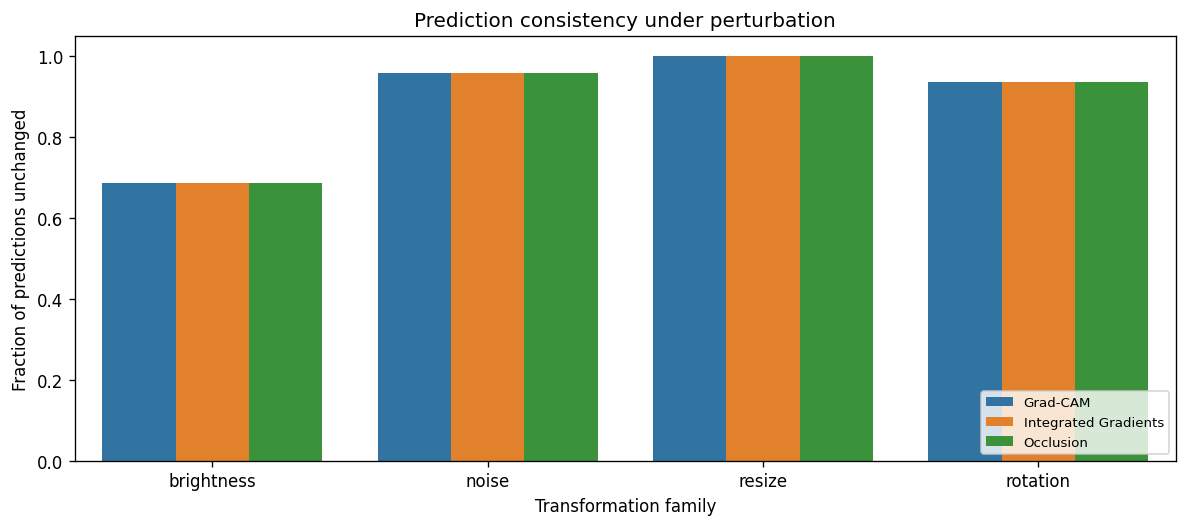

In [11]:
figure, axis = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=summary, x="transformation", y="prediction_consistency", hue="method", ax=axis)
axis.set(
    title="Prediction consistency under perturbation",
    xlabel="Transformation family",
    ylabel="Fraction of predictions unchanged",
    ylim=(0, 1.05),
)
axis.legend(loc="lower right", fontsize=8)
figure.tight_layout()
figure.savefig(Path("figures") / "stability_prediction_consistency.png", dpi=300)
display(DisplayImage(filename=str(Path("figures") / "stability_prediction_consistency.png")))

## Interpretation guide

- **Higher SSIM, Spearman, and cosine values** indicate that the explanation map preserves structure, ranking, and orientation under the perturbation. These are complementary, not interchangeable.
- **Prediction consistency** is a property of the classifier, not of the explanation method. Report it whenever stability is discussed, because similarity scores are conditional on it.
- **Dose–response patterns** in the parameter table are more informative than family-level means. For example, stability should degrade as rotation angle or noise level increases.
- **Do not rank methods from a single transformation.** The combined raw table is the input to Notebook 05, where per-sample aggregation and weighting sensitivity are handled explicitly.

Proceed to `05_proposed_method.ipynb`.